# Train the on / off / noise classifier
Kept separate from `explore_dataset.ipynb` (plots / image export). Features come from `tools/voice_features.py`, the same definitions the firmware will use.

**Protocol (so the final number is honest)**
1. Split once: 75 % train (225 clips), 25 % test (75 clips). The test set is touched **once, at the very end**.
2. Every decision (scaling, outlier handling, which features, which model, regularisation) is made with repeated 5-fold cross-validation **on the training clips only**.
3. Scalers and transforms live *inside* the cross-validation pipeline, so each fold fits them on its own training part only (no leakage).

Caveat: splits are random across clips, not speakers; a voice the model never heard will score lower.

In [1]:
import sys, warnings
sys.path.insert(0, "../tools")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import voice_features as vf
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import (FunctionTransformer, MinMaxScaler, PowerTransformer,
                                   QuantileTransformer, RobustScaler, StandardScaler)
from sklearn.tree import DecisionTreeClassifier

names = vf.FEATURE_NAMES
X, y, paths = vf.load_dataset("../dataset")
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=0)      # 25 scores per estimate
print(X.shape, "train", Xtr.shape, "test", Xte.shape, dict(zip(*np.unique(y, return_counts=True))))

(500, 11) train (375, 11) test (125, 11) {np.str_('blue'): np.int64(100), np.str_('green'): np.int64(100), np.str_('noise'): np.int64(100), np.str_('off'): np.int64(100), np.str_('on'): np.int64(100)}


## 1. Audit the features (training clips only)
- **skew**: 0 = symmetric; |skew| > 1 = long tail, which distorts z-scoring and linear models.
- **% beyond 3 sd** and **% beyond 1.5 IQR**: how many clips are outliers. Outliers drag the mean and standard deviation, which is what z-scoring uses.

In [2]:
tr = pd.DataFrame(Xtr, columns=names)
q1, q3 = tr.quantile(0.25), tr.quantile(0.75)
audit = pd.DataFrame({
    "min": tr.min(), "median": tr.median(), "max": tr.max(),
    "skew": tr.apply(stats.skew),
    "% beyond 3 sd": ((tr - tr.mean()).abs() > 3 * tr.std()).mean() * 100,
    "% beyond 1.5 IQR": ((tr < q1 - 1.5 * (q3 - q1)) | (tr > q3 + 1.5 * (q3 - q1))).mean() * 100,
})
audit.round(3)

,min,median,max,skew,% beyond 3 sd,% beyond 1.5 IQR
dur,0.016,0.576,0.752,-1.263,0.000,11.467
span,0.016,0.944,0.992,-1.912,0.000,10.133
peak_db,8.611,42.209,63.223,-0.547,0.000,4.800
b0,0.069,0.454,0.966,0.185,0.000,0.000
b1,0.003,0.069,0.811,0.790,0.000,0.000
b2,0.000,0.004,0.234,2.596,3.467,9.067
b3,0.000,0.003,0.377,5.255,2.667,16.000
cent,85.729,338.890,2079.226,2.421,2.133,5.333
hipos,0.000,0.569,1.000,-0.636,0.000,11.200
zcr,0.001,0.019,0.089,1.706,1.867,5.867


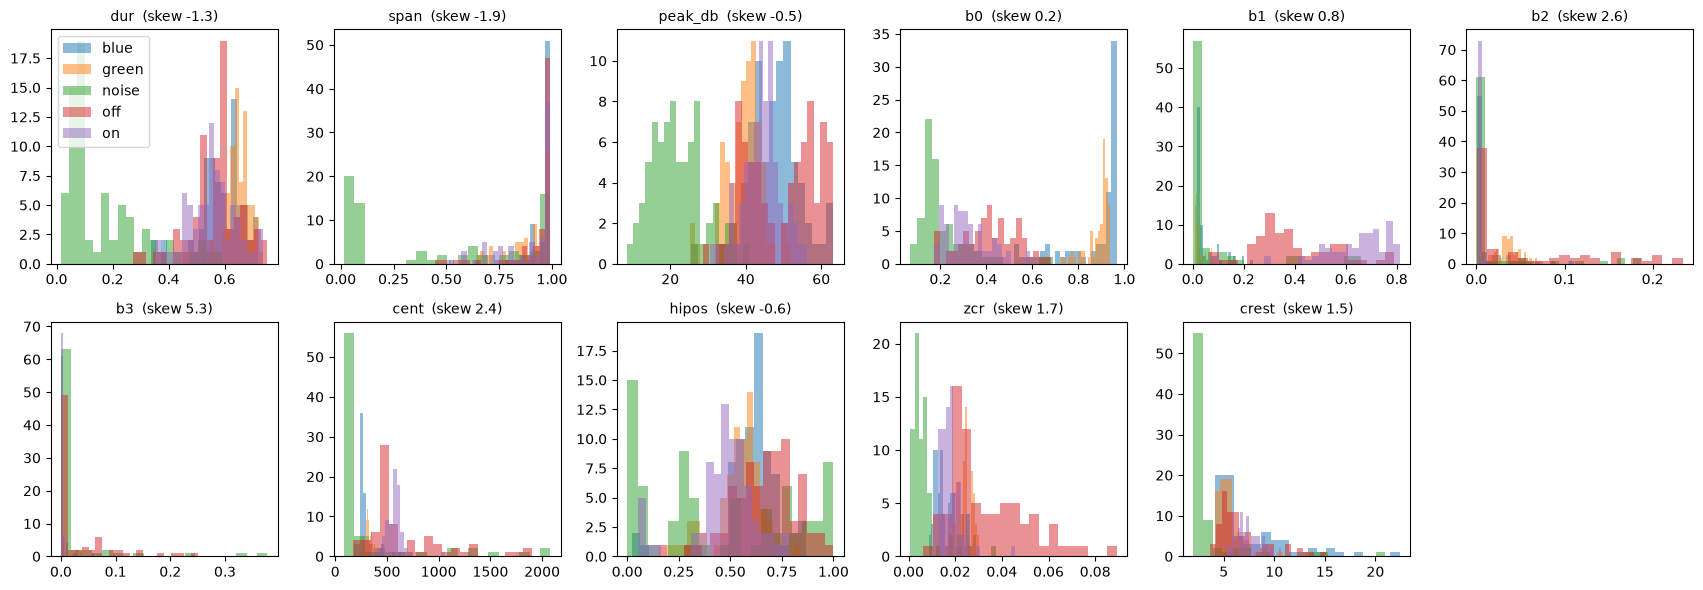

In [3]:
fig, axs = plt.subplots(2, 6, figsize=(17, 6))
for ax, (i, n) in zip(axs.flat, enumerate(names)):
    for c in np.unique(ytr):
        ax.hist(Xtr[ytr == c, i], bins=20, alpha=0.5, label=c)
    ax.set_title(f"{n}  (skew {audit.loc[n, 'skew']:.1f})", fontsize=10)
axs.flat[0].legend(); axs.flat[-1].axis("off"); fig.tight_layout()

## 2. Redundancy between features
Highly correlated features carry the same information twice. The four bands `b0..b3` are shares of one total, so they are also tied together (they sum to roughly 1).

b3  cent    0.83
dtype: float64

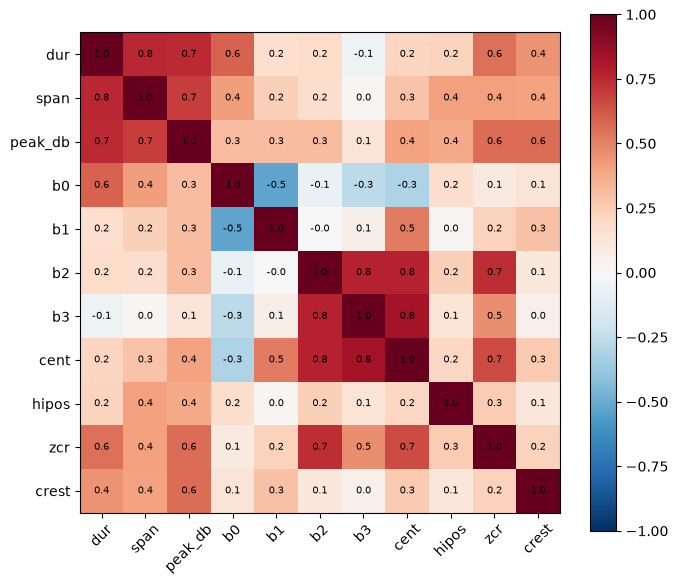

In [4]:
corr = tr.corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(names)), names, rotation=45); ax.set_yticks(range(len(names)), names)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7)
fig.colorbar(im); fig.tight_layout()
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
pairs[pairs.abs() > 0.8].sort_values(key=abs, ascending=False).round(2)

## 3. Scaling and outlier handling: which treatment works best?
Candidates, each fitted on the training part of every fold only:
- **raw**: no scaling (shows why scaling matters for distance and linear models)
- **z-score**: (x - mean) / sd, the default, sensitive to outliers
- **min-max**: squeezes to [0, 1] using the extremes, the most outlier-sensitive of all
- **robust**: (x - median) / IQR, ignores the tails when scaling
- **z-score + clip ±3σ**: z-score, then cap anything beyond 3 sd (winsorising)
- **log(skewed) + z-score / robust**: log-transform the long-tailed positive features first
- **quantile → normal / power (Yeo-Johnson)**: remap each feature's distribution towards a bell curve

Tree models (random forest, decision tree) only compare values to thresholds, so they are unaffected by monotone scaling and are not part of this comparison.

log-transformed in the 'log(skewed)' variants: ['b2', 'b3', 'cent', 'zcr', 'crest']


,logistic regression,k-NN (k=5),LR std
raw (no scaling),81.8,76.1,4.0
z-score,92.1,90.7,3.2
min-max,87.8,90.5,3.5
robust (median/IQR),92.4,86.6,3.3
z-score + clip 3 sd,92.3,91.4,2.9
log(skewed) + z-score,92.3,91.4,3.1
log(skewed) + robust,91.8,89.1,3.3
quantile -> normal,91.0,89.1,3.5
power (Yeo-Johnson),92.9,91.1,2.8


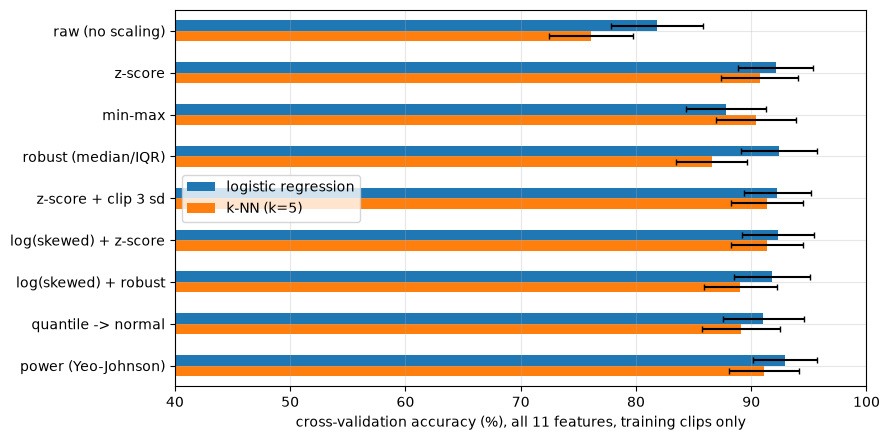

In [5]:
skewed = [n for n in names if audit.loc[n, "skew"] > 1 and audit.loc[n, "min"] >= 0]
print("log-transformed in the 'log(skewed)' variants:", skewed)
log_idx = [names.index(n) for n in skewed]
def logskew(A):                         # stateless (no fitted parameters), so no leakage
    A = A.copy(); A[:, log_idx] = np.log(A[:, log_idx] + 1e-3); return A
ident = lambda A: A
clip3 = lambda: make_pipeline(StandardScaler(), FunctionTransformer(lambda a: np.clip(a, -3, 3)))

PRE = {  # name -> (stateless transform of the raw matrix, fitted scaler factory or None)
    "raw (no scaling)":        (ident,   None),
    "z-score":                 (ident,   StandardScaler),
    "min-max":                 (ident,   MinMaxScaler),
    "robust (median/IQR)":     (ident,   RobustScaler),
    "z-score + clip 3 sd":     (ident,   clip3),
    "log(skewed) + z-score":   (logskew, StandardScaler),
    "log(skewed) + robust":    (logskew, RobustScaler),
    "quantile -> normal":      (ident,   lambda: QuantileTransformer(n_quantiles=100, output_distribution="normal")),
    "power (Yeo-Johnson)":     (ident,   PowerTransformer),
}
XT  = {k: fn(Xtr) for k, (fn, _) in PRE.items()}       # transformed training matrices
XTE = {k: fn(Xte) for k, (fn, _) in PRE.items()}

def pipe(key, clf):
    sc = PRE[key][1]
    return make_pipeline(sc(), clf) if sc else make_pipeline(clf)
def cv_acc(key, clf, cols=None):
    cols = list(range(len(names))) if cols is None else cols
    return cross_val_score(pipe(key, clf), XT[key][:, cols], ytr, cv=cv)

LR = lambda C=1.0: LogisticRegression(C=C, max_iter=5000)
KNN = lambda: KNeighborsClassifier(5)
res = {k: {"logistic regression": cv_acc(k, LR()), "k-NN (k=5)": cv_acc(k, KNN())} for k in PRE}
tab = pd.DataFrame({m: {k: res[k][m].mean() * 100 for k in PRE} for m in ["logistic regression", "k-NN (k=5)"]})
tab_sd = pd.DataFrame({m: {k: res[k][m].std() * 100 for k in PRE} for m in ["logistic regression", "k-NN (k=5)"]})
fig, ax = plt.subplots(figsize=(9, 4.5))
tab.plot.barh(ax=ax, xerr=tab_sd, capsize=2); ax.set_xlim(40, 100); ax.invert_yaxis(); ax.grid(alpha=0.3)
ax.set_xlabel("cross-validation accuracy (%), all 11 features, training clips only"); fig.tight_layout()
tab.round(1).assign(**{"LR std": tab_sd["logistic regression"].round(1)})

Differences smaller than about one standard deviation (the `LR std` column) are noise. The practical question is whether a treatment is clearly worse (e.g. raw, min-max) or clearly better than plain z-score.

In [6]:
best_pre = tab["logistic regression"].idxmax()
print("best preprocessing for logistic regression:", best_pre, f"({tab.loc[best_pre, 'logistic regression']:.1f} %)")
print("plain z-score:", f"{tab.loc['z-score', 'logistic regression']:.1f} %")

best preprocessing for logistic regression: power (Yeo-Johnson) (92.9 %)
plain z-score: 92.1 %


## 4. How much does each feature actually contribute?
Four views, all with logistic regression on the best preprocessing:
1. **Drop-one ablation**: remove one feature, retrain, see how much accuracy falls.
2. **Alone**: accuracy using that single feature (a lone feature can look weak but still add something in combination).
3. **Permutation importance**: shuffle one feature in the validation fold of an already-trained model; the accuracy drop is how much the model relies on it.
4. **Greedy forward selection**: add the feature that helps most, one at a time.

full model, all 11 features (power (Yeo-Johnson)): 92.9 +- 2.8 %


,drop-one (pts),alone (%),permutation (pts)
b1,-1.17,51.6,21.91
b2,-1.71,37.5,18.63
zcr,-1.60,57.1,12.50
b0,-0.80,58.4,12.30
peak_db,-0.43,51.6,11.15
hipos,-0.21,34.0,6.33
cent,-0.32,59.0,5.85
crest,0.43,45.7,3.65
b3,-0.37,40.4,2.99
span,-0.43,33.9,2.15


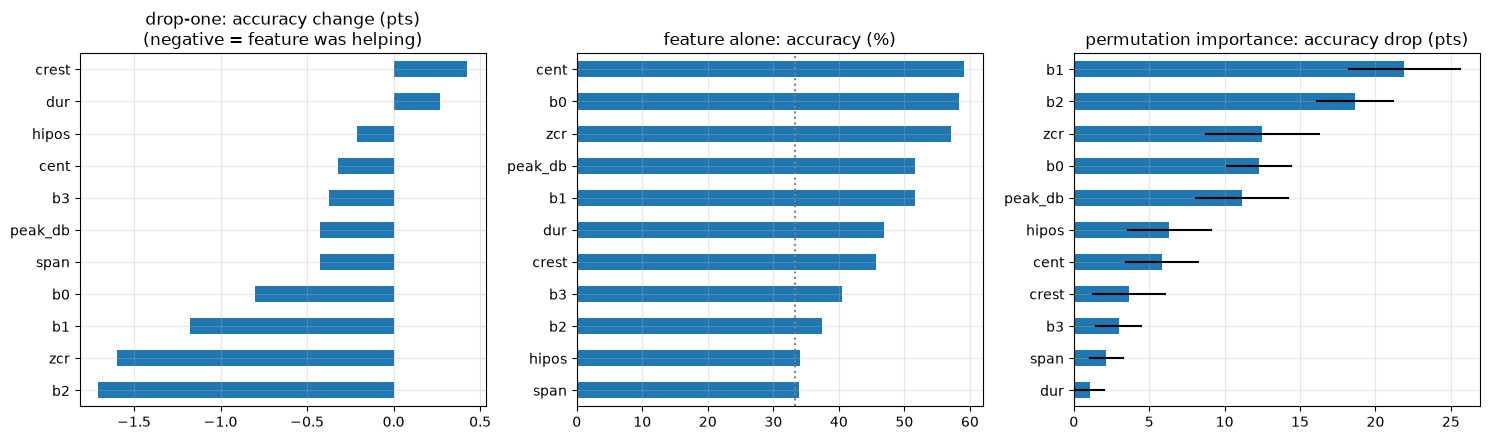

In [7]:
KEY = best_pre
allc = list(range(len(names)))
full = cv_acc(KEY, LR())
abl = pd.Series({n: (cv_acc(KEY, LR(), [j for j in allc if j != i]).mean() - full.mean()) * 100 for i, n in enumerate(names)})
alone = pd.Series({n: cv_acc(KEY, LR(), [i]).mean() * 100 for i, n in enumerate(names)})

rng = np.random.default_rng(0)
drops = np.zeros((cv.get_n_splits(), len(names)))
for k, (a, b) in enumerate(cv.split(XT[KEY], ytr)):
    m = pipe(KEY, LR()).fit(XT[KEY][a], ytr[a]); base = m.score(XT[KEY][b], ytr[b])
    for j in allc:
        d = []
        for _ in range(5):
            Xp = XT[KEY][b].copy(); Xp[:, j] = rng.permutation(Xp[:, j]); d.append(base - m.score(Xp, ytr[b]))
        drops[k, j] = np.mean(d)
perm = pd.Series(drops.mean(0) * 100, index=names); perm_sd = pd.Series(drops.std(0) * 100, index=names)

fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))
abl.sort_values().plot.barh(ax=axs[0]); axs[0].set_title("drop-one: accuracy change (pts)\n(negative = feature was helping)")
alone.sort_values().plot.barh(ax=axs[1]); axs[1].set_title("feature alone: accuracy (%)"); axs[1].axvline(100 / 3, color="gray", ls=":")
perm.sort_values().plot.barh(ax=axs[2], xerr=perm_sd[perm.sort_values().index]); axs[2].set_title("permutation importance: accuracy drop (pts)")
for a in axs: a.grid(alpha=0.3)
fig.tight_layout()
print(f"full model, all 11 features ({KEY}): {full.mean() * 100:.1f} +- {full.std() * 100:.1f} %")
pd.DataFrame({"drop-one (pts)": abl.round(2), "alone (%)": alone.round(1), "permutation (pts)": perm.round(2)}).sort_values("permutation (pts)", ascending=False)

,added,CV acc %,std
1,cent,59.0,5.3
2,b2,75.8,4.7
3,b0,85.2,4.4
4,zcr,88.4,3.5
5,b1,91.1,3.3
6,dur,92.7,2.9
7,crest,93.1,3.1
8,b3,93.4,2.8
9,peak_db,93.1,2.4
10,span,92.7,2.4


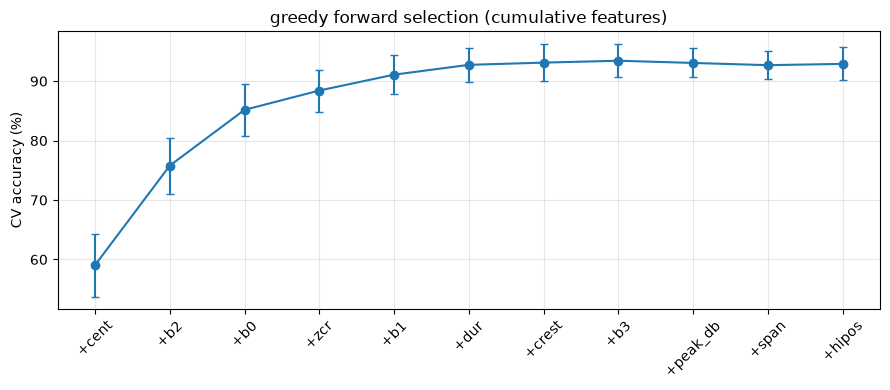

In [8]:
chosen, remaining, curve = [], allc[:], []
while remaining:
    scored = {j: cv_acc(KEY, LR(), chosen + [j]) for j in remaining}
    j = max(scored, key=lambda k: scored[k].mean())
    chosen.append(j); remaining.remove(j); curve.append((scored[j].mean() * 100, scored[j].std() * 100))
order = [names[j] for j in chosen]
mu, sd = np.array(curve).T
fig, ax = plt.subplots(figsize=(9, 4))
ax.errorbar(range(1, len(mu) + 1), mu, sd, marker="o", capsize=3)
ax.set_xticks(range(1, len(mu) + 1), [f"+{n}" for n in order], rotation=45)
ax.set_ylabel("CV accuracy (%)"); ax.set_title("greedy forward selection (cumulative features)"); ax.grid(alpha=0.3); fig.tight_layout()
pd.DataFrame({"added": order, "CV acc %": mu.round(1), "std": sd.round(1)}, index=range(1, len(mu) + 1))

In [9]:
# Smallest feature set within one standard error of the best, so extra features must earn their place.
best_k = int(np.argmax(mu))
se = sd[best_k] / np.sqrt(cv.get_n_splits())
k_min = next(k for k in range(len(mu)) if mu[k] >= mu[best_k] - se)
FEATS = chosen[:k_min + 1]
print(f"best at {best_k + 1} features ({mu[best_k]:.1f} %); smallest within 1 SE: {k_min + 1} features -> {[names[j] for j in FEATS]}")
sets = {"all 11": allc,
        "earlier 9 (bands + shape)": [names.index(n) for n in ["b0", "b1", "b2", "b3", "cent", "dur", "crest", "zcr", "hipos"]],
        f"greedy {k_min + 1}": FEATS}
pd.DataFrame({k: {"CV acc %": cv_acc(KEY, LR(), c).mean() * 100, "std": cv_acc(KEY, LR(), c).std() * 100, "n features": len(c)} for k, c in sets.items()}).T.round(1)

best at 8 features (93.4 %); smallest within 1 SE: 7 features -> ['cent', 'b2', 'b0', 'zcr', 'b1', 'dur', 'crest']


,CV acc %,std,n features
all 11,92.9,2.8,11.0
earlier 9 (bands + shape),92.0,3.1,9.0
greedy 7,93.1,3.1,7.0


## 5. Regularisation and model family
`C` in logistic regression is the inverse regularisation strength: small C = simpler model, less affected by outliers and correlated features. Then the model families on the chosen features and preprocessing.

best C: 10 (93.6 %)


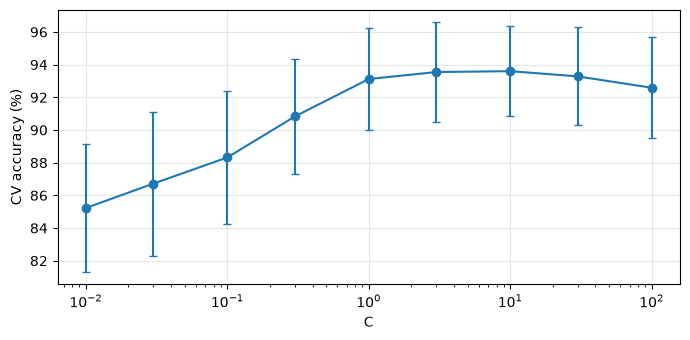

In [10]:
Cs = [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100]
cs = {c: cv_acc(KEY, LR(c), FEATS) for c in Cs}
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.errorbar(Cs, [v.mean() * 100 for v in cs.values()], [v.std() * 100 for v in cs.values()], marker="o", capsize=3)
ax.set_xscale("log"); ax.set_xlabel("C"); ax.set_ylabel("CV accuracy (%)"); ax.grid(alpha=0.3); fig.tight_layout()
best_C = max(cs, key=lambda c: cs[c].mean()); print("best C:", best_C, f"({cs[best_C].mean() * 100:.1f} %)")

,mean %,std %
nearest centroid,84.7,4.1
k-NN (k=5),91.6,4.1
logistic regression (C=10),93.6,2.7
decision tree (depth 4),86.3,4.1
random forest (100 trees),93.7,3.3


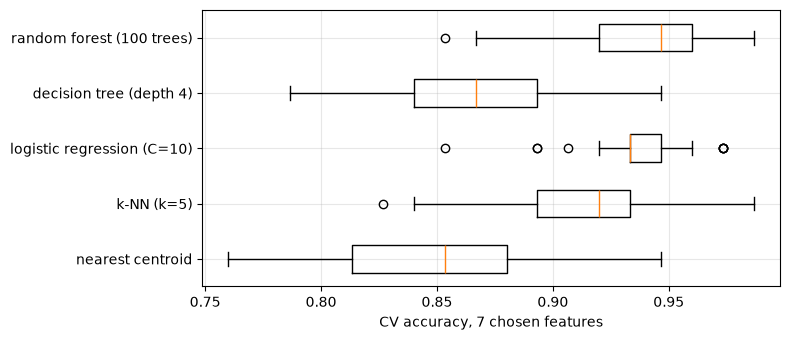

In [11]:
MODELS = {
    "nearest centroid": (KEY, NearestCentroid()),
    "k-NN (k=5)": (KEY, KNN()),
    f"logistic regression (C={best_C})": (KEY, LR(best_C)),
    "decision tree (depth 4)": ("raw (no scaling)", DecisionTreeClassifier(max_depth=4, random_state=0)),
    "random forest (100 trees)": ("raw (no scaling)", RandomForestClassifier(100, random_state=0)),
}
sc = {n: cv_acc(k, c, FEATS) for n, (k, c) in MODELS.items()}
fig, ax = plt.subplots(figsize=(8, 3.5)); ax.boxplot(list(sc.values()), tick_labels=list(sc), orientation="horizontal")
ax.set_xlabel(f"CV accuracy, {len(FEATS)} chosen features"); ax.grid(alpha=0.3); fig.tight_layout()
pd.DataFrame({"mean %": {n: v.mean() * 100 for n, v in sc.items()}, "std %": {n: v.std() * 100 for n, v in sc.items()}}).round(1)

## 6. Accuracy vs number of training recordings
Learning curve for the chosen logistic regression, a nearest-centroid baseline and a random forest. Each point averages 20 random splits (20 test clips per class held out each time) taken from all clips.

,"logistic regression, 7 features","nearest centroid, 9 features","random forest, all 11"
clips/class,,,
3,80 +- 6,79 +- 5,80 +- 4
5,83 +- 5,81 +- 4,85 +- 4
8,86 +- 4,82 +- 4,86 +- 3
10,88 +- 3,82 +- 3,87 +- 3
15,90 +- 2,83 +- 4,89 +- 3
20,91 +- 2,83 +- 4,89 +- 3
30,92 +- 2,82 +- 3,90 +- 2
40,93 +- 2,82 +- 3,91 +- 2
60,94 +- 2,82 +- 3,93 +- 2


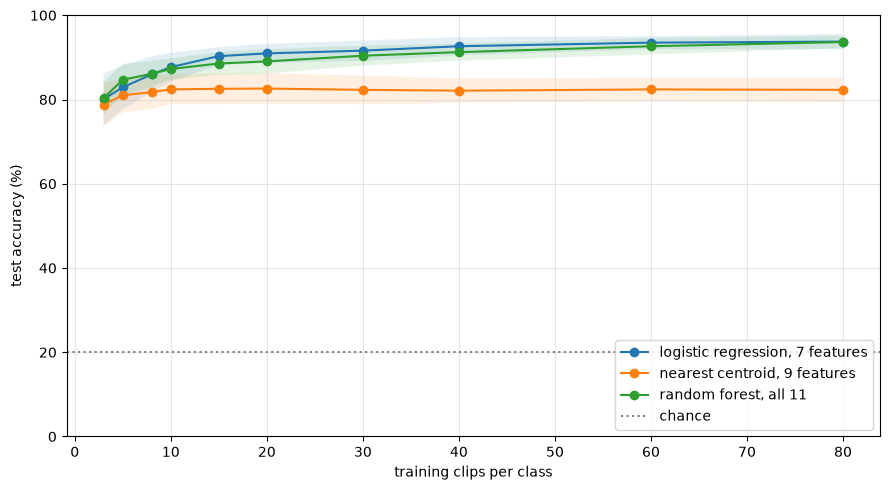

In [12]:
classes = list(np.unique(y)); N_TEST, REPEATS = 20, 20
Xl = {k: fn(X) for k, (fn, _) in PRE.items()}
LC = {f"logistic regression, {len(FEATS)} features": (KEY, LR(best_C), FEATS),
      "nearest centroid, 9 features": (KEY, NearestCentroid(), sets["earlier 9 (bands + shape)"]),
      "random forest, all 11": ("raw (no scaling)", RandomForestClassifier(100, random_state=0), allc)}
sizes = [n for n in (3, 5, 8, 10, 15, 20, 30, 40, 60, 80) if n <= min((y == c).sum() for c in classes) - N_TEST]
rng = np.random.default_rng(0); acc = {k: np.zeros((REPEATS, len(sizes))) for k in LC}
idx_by = {c: np.where(y == c)[0] for c in classes}
for r in range(REPEATS):
    perm_ = {c: rng.permutation(idx_by[c]) for c in classes}
    te = np.concatenate([perm_[c][:N_TEST] for c in classes])
    for j, n in enumerate(sizes):
        trn = np.concatenate([perm_[c][N_TEST:N_TEST + n] for c in classes])
        for name, (key, clf, cols) in LC.items():
            m = pipe(key, clone(clf)).fit(Xl[key][trn][:, cols], y[trn]); acc[name][r, j] = m.score(Xl[key][te][:, cols], y[te])
fig, ax = plt.subplots(figsize=(9, 5))
for name, a in acc.items():
    ax.plot(sizes, a.mean(0) * 100, marker="o", label=name); ax.fill_between(sizes, (a.mean(0) - a.std(0)) * 100, (a.mean(0) + a.std(0)) * 100, alpha=0.12)
ax.axhline(100 / len(classes), color="gray", ls=":", label="chance"); ax.set_ylim(0, 100)
ax.set_xlabel("training clips per class"); ax.set_ylabel("test accuracy (%)"); ax.grid(alpha=0.3); ax.legend(loc="lower right"); fig.tight_layout()
pd.DataFrame({n: [f"{m * 100:.0f} +- {s * 100:.0f}" for m, s in zip(a.mean(0), a.std(0))] for n, a in acc.items()}, index=pd.Index(sizes, name="clips/class"))

## 7. Final test, touched once
Train on all 225 training clips with the choices made above, then score the 75 held-out clips. Also shown: the earlier setup (plain z-score, 9 features, C=1) and a random forest, on the same test clips. With only 75 test clips the 95 % interval is wide, so differences of a few points are not meaningful.

              precision    recall  f1-score   support

        blue       0.96      0.96      0.96        25
       green       0.96      1.00      0.98        25
       noise       1.00      0.92      0.96        25
         off       0.86      1.00      0.93        25
          on       1.00      0.88      0.94        25

    accuracy                           0.95       125
   macro avg       0.96      0.95      0.95       125
weighted avg       0.96      0.95      0.95       125



,correct,acc,ci95
model,,,
"FINAL: LR C=10, 7 features, power (Yeo-Johnson)",119/125,95.2 %,90-98 %
"earlier: LR C=1, 9 features, z-score",114/125,91.2 %,85-95 %
"random forest, all 11",120/125,96.0 %,91-98 %


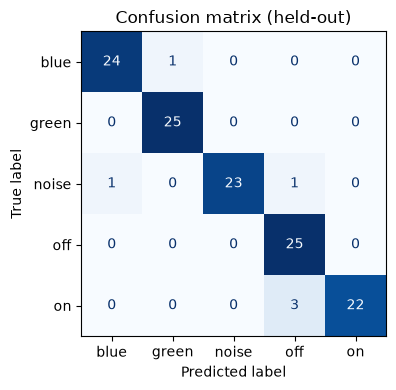

In [13]:
def evaluate(label, key, clf, cols):
    m = pipe(key, clf).fit(XT[key][:, cols], ytr); pred = m.predict(XTE[key][:, cols]); k = int((pred == yte).sum())
    lo, hi = stats.binomtest(k, len(yte)).proportion_ci(0.95, method="wilson")
    return m, pred, dict(model=label, correct=f"{k}/{len(yte)}", acc=f"{k / len(yte) * 100:.1f} %", ci95=f"{lo * 100:.0f}-{hi * 100:.0f} %")
final, pred, row = evaluate(f"FINAL: LR C={best_C}, {len(FEATS)} features, {KEY}", KEY, LR(best_C), FEATS)
rows = [row,
        evaluate("earlier: LR C=1, 9 features, z-score", "z-score", LR(), sets["earlier 9 (bands + shape)"])[2],
        evaluate("random forest, all 11", "raw (no scaling)", RandomForestClassifier(100, random_state=0), allc)[2]]
print(classification_report(yte, pred, digits=2))
fig, ax = plt.subplots(figsize=(4.5, 4)); ConfusionMatrixDisplay.from_predictions(yte, pred, ax=ax, colorbar=False, cmap="Blues")
ax.set_title("Confusion matrix (held-out)"); fig.tight_layout()
pd.DataFrame(rows).set_index("model")

## 8. What the final model learned
Weights are per standardised feature, so their sizes are comparable; positive pushes towards that class. Interpret with care for correlated features (section 2).

54 floats = 216 bytes of flash for the model + scaler


,blue,green,noise,off,on
cent,2.53,-3.99,-0.12,-1.66,3.24
b2,-0.41,5.09,0.29,-1.43,-3.54
b0,2.47,2.90,-3.46,-1.48,-0.43
zcr,-1.63,1.20,-1.03,2.09,-0.64
b1,-2.49,-5.72,0.10,3.35,4.76
dur,0.78,1.80,-2.58,-0.58,0.58
crest,0.55,-0.88,-0.09,-0.76,1.19


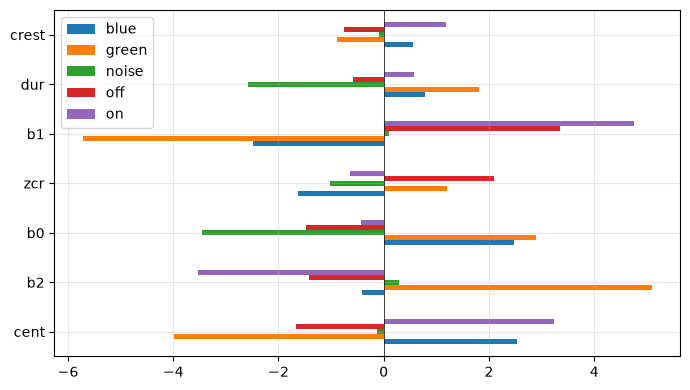

In [14]:
lr = final[-1]
W = pd.DataFrame(lr.coef_.T, index=[names[j] for j in FEATS], columns=lr.classes_)
fig, ax = plt.subplots(figsize=(7, 4)); W.plot.barh(ax=ax); ax.axvline(0, color="k", lw=0.5); ax.grid(alpha=0.3); fig.tight_layout()
n_params = lr.coef_.size + lr.intercept_.size + 2 * len(FEATS)
print(f"{n_params} floats = {n_params * 4} bytes of flash for the model + scaler")
W.round(2)